# Hälsostudie - Grundläggande analys och statistik

In [12]:
import pandas as pd
import numpy as np
from scipy import stats
import src.viz as v

df = pd.read_csv("health_study_dataset.csv")

In [13]:
print(f"Datamängdens storlek: {len(df)}")

display(df.info())

Datamängdens storlek: 800
<class 'pandas.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   id           800 non-null    int64  
 1   age          800 non-null    int64  
 2   sex          800 non-null    str    
 3   height       800 non-null    float64
 4   weight       800 non-null    float64
 5   systolic_bp  800 non-null    float64
 6   cholesterol  800 non-null    float64
 7   smoker       800 non-null    str    
 8   disease      800 non-null    int64  
dtypes: float64(4), int64(3), str(2)
memory usage: 56.4 KB


None

## Beskrivande analys

In [14]:
avg = df[["age", "height", "weight", "systolic_bp", "cholesterol"]].agg(
    ["mean", "median", "min", "max"]).round(2)
avg


,age,height,weight,systolic_bp,cholesterol
mean,49.43,171.85,73.41,149.18,4.93
median,50.00,171.35,73.20,149.40,4.97
min,18.00,144.40,33.70,106.80,2.50
max,90.00,200.40,114.40,185.90,7.88


### Korrelationstabell

In [15]:
df_copy = df.copy()

df_copy = df_copy.drop(columns="id")
df_copy["bmi"] = df_copy["weight"] / (df_copy["height"] / 100) ** 2
df_copy["sex"] = (df["sex"] == "M").astype(int)         # M = 1, F = 0
df_copy["smoker"] = (df["smoker"] == "Yes").astype(int) # Yes = 1, No = 0
corr_matrix = df_copy.corr().round(2)

display(corr_matrix)

,age,sex,height,weight,systolic_bp,cholesterol,smoker,disease,bmi
age,1.00,-0.03,-0.00,-0.02,0.61,0.49,0.04,0.02,-0.01
sex,-0.03,1.00,0.69,0.46,0.08,0.05,-0.05,0.06,0.03
height,-0.00,0.69,1.00,0.32,0.09,-0.04,-0.05,0.03,-0.30
weight,-0.02,0.46,0.32,1.00,0.18,0.26,0.02,0.04,0.80
systolic_bp,0.61,0.08,0.09,0.18,1.00,0.37,0.02,0.03,0.13
cholesterol,0.49,0.05,-0.04,0.26,0.37,1.00,0.01,0.01,0.29
smoker,0.04,-0.05,-0.05,0.02,0.02,0.01,1.00,0.08,0.05
disease,0.02,0.06,0.03,0.04,0.03,0.01,0.08,1.00,0.02
bmi,-0.01,0.03,-0.30,0.80,0.13,0.29,0.05,0.02,1.00


### Diagram

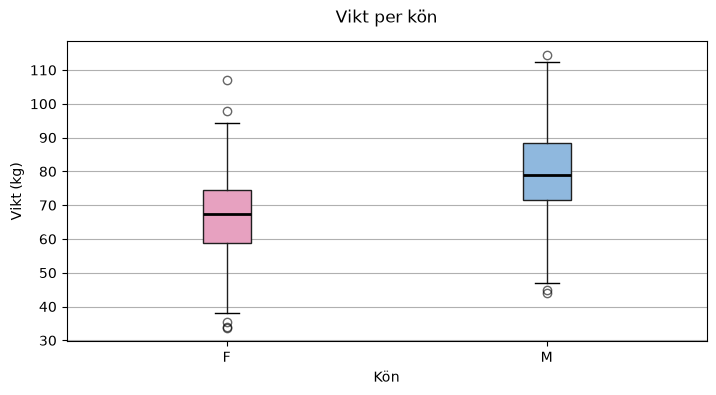

In [16]:
v.boxplot_weight_gender(df)

Män har högre medianvikt än kvinnor. Det finns några extremvärden i båda grupperna.

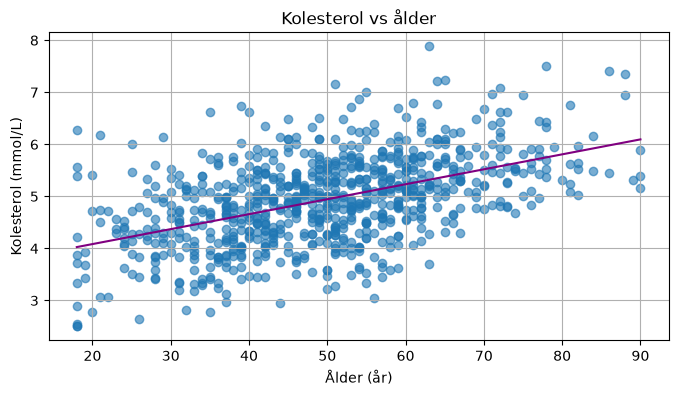

In [17]:
v.scatter_cholesterol(df)

Korrelationen mellan Kolesterol och ålder är ≈ 0,49. Punkterna visar att kolesterolet tenderar att öka med åldern, men spridningen är stor.

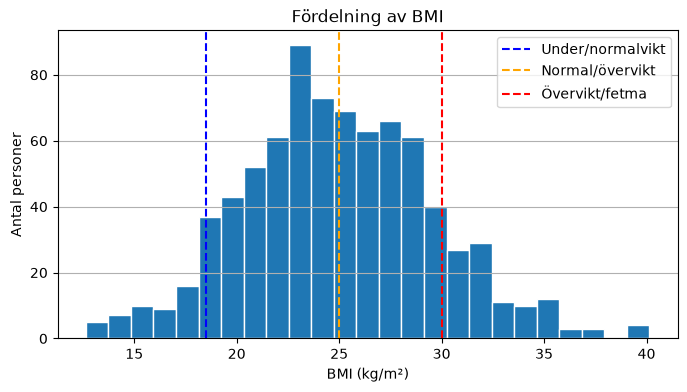

In [18]:
v.hist_bmi(df_copy)

Normalvikt (BMI 18,5–24,9) är den vanligaste kategorin, men många ligger inom övervikt (25–29,9) och fetma (30 eller mer).

## Simulering: andel sjuka

In [19]:
rng = np.random.default_rng(15)

with_disease = int(df["disease"].sum())
mean_disease = df["disease"].mean()

sample = rng.binomial(n=1, p=mean_disease, size=1000)
se_disease = np.sqrt(mean_disease * (1 - mean_disease) / 1000)

comparison = pd.DataFrame({
    "Antal personer": [len(df), len(sample)],
    "Antal sjuka": [int(df["disease"].sum()), int(sample.sum())],
    "Andel sjuka": [mean_disease, sample.mean()],
}, index=["Dataset", "Simulering"])

print(f"""
Totalt antal personer med sjukdomen: {with_disease} av {df.disease.count()}
Andelen personer med sjukdomen: {mean_disease} ({mean_disease*100}%)
""")
display(comparison.style.format({"Andel sjuka": "{:.3%}"}))
print(f"Standardfel (SE): {se_disease:.3%}")


Totalt antal personer med sjukdomen: 47 av 800
Andelen personer med sjukdomen: 0.05875 (5.875%)



,Antal personer,Antal sjuka,Andel sjuka
Dataset,800,47,5.875%
Simulering,1000,54,5.400%


Standardfel (SE): 0.744%


Andelen sjuka i datasetet är 5,875 % (47 av 800). I simuleringen med 1000 personer blev andelen 5,4 %. Skillnaden på ungefär 0,5 är mindre än standardfelet (ca 0,7 procentenheter) och beror därför troligen på slumpen.

## Konfidensintervall för medelvärdet av systolic_bp

In [20]:
rng_boot = np.random.default_rng(33)

bp = df.systolic_bp.values
n_bp = bp.size
mean_bp = df.systolic_bp.mean()
sd_bp = bp.std(ddof=1)
se_bp = sd_bp / np.sqrt(n_bp)

t_crit = stats.t.ppf(0.975, df=n_bp-1)

ci_low_t = mean_bp - t_crit * se_bp
ci_high_t = mean_bp + t_crit * se_bp

# Bootstrap
n_boot = 10_000
boot_means = []
for _ in range(n_boot):
    boot_sample = rng_boot.choice(bp, size=n_bp, replace=True)
    boot_means.append(boot_sample.mean())
ci_low_boot, ci_high_boot = np.percentile(boot_means, [2.5, 97.5])

print(f"n = {n_bp}, medel = {mean_bp:.3f} mmHg, SD = {sd_bp:.3f}, SE = {se_bp:.3f}")

ci_table = pd.DataFrame({
    "Nedre gräns": [ci_low_t, ci_low_boot],
    "Övre gräns": [ci_high_t, ci_high_boot],
    "Bredd": [ci_high_t - ci_low_t, ci_high_boot - ci_low_boot],
}, index=["t-fördelning", "Bootstrap"]).round(3)

display(ci_table)

n = 800, medel = 149.179 mmHg, SD = 12.793, SE = 0.452


,Nedre gräns,Övre gräns,Bredd
t-fördelning,148.291,150.066,1.776
Bootstrap,148.264,150.061,1.797


Ett 95 % konfidensintervall för medelvärdet är 148,3–150,1 mmHg.
Båda metoderna ger nästan samma intervall (ca 148,3–150,1 mmHg). Det beror på att stickprovet är stort (n = 800), så medelvärdet blir ungefär normalfördelat.

## Hypotesprövning:

### Har rökare högre medel-blodtryck än icke-rökare?
**Hypoteser**  
H₀: Rökare = Icke-rökare  
H₁: Rökare > Icke-rökare

In [21]:
smoker_yes = df.loc[df.smoker == "Yes", "systolic_bp"].values
smoker_no = df.loc[df.smoker == "No", "systolic_bp"].values

n_smoker, n_no_smoker = len(smoker_yes), len(smoker_no)
mean_smoker, mean_no_smoker = smoker_yes.mean(), smoker_no.mean()
sd_smoker, sd_no_smoker = smoker_yes.std(ddof=1), smoker_no.std(ddof=1)
diff = mean_smoker - mean_no_smoker

# One-tailed t-test, Welch variant
t_stat, p_one = stats.ttest_ind(
    smoker_yes, smoker_no,
    equal_var=False,
    alternative="greater")

alpha = 0.05

group = pd.DataFrame({
    "n": [n_smoker, n_no_smoker],
    "Medel (mmHg)": [mean_smoker, mean_no_smoker],
    "SD": [sd_smoker, sd_no_smoker],
}, index=["Rökare", "Icke-rökare"]).round(3)

result = pd.Series({
    "Skillnad i medelvärde": f"{diff:.3f} mmHg",
    "t-värde": f"{t_stat:.3f}",
    "p-värde (ensidigt)": f"{p_one:.4f}",
    "Beslut": "Förkasta H0" if p_one < alpha else "Förkasta inte H0",
}, name="Rökare > Icke-rökare")

display(group)
display(result)

,n,Medel (mmHg),SD
Rökare,213,149.525,13.268
Icke-rökare,587,149.053,12.626


Skillnad i medelvärde          0.472 mmHg
t-värde                             0.450
p-värde (ensidigt)                 0.3264
Beslut                   Förkasta inte H0
Name: Rökare > Icke-rökare, dtype: str

Skillnaden är 0,47 mmHg (149,5 mot 149,1), med t = 0,45 och p = 0,33. Eftersom p > 0,05 kan vi **inte förkasta H₀**. Vi har alltså **inget stöd** för att rökare har högre medelblodtryck.

## Power Simulering

In [22]:
rng_power = np.random.default_rng(2)

def simulate_power(diff, n_sim=10_000, alpha=0.05):
    significant = 0

    for _ in range(n_sim):
        sample_no_smoker = rng_power.normal(mean_no_smoker, sd_no_smoker, n_no_smoker)
        sample_smoker = rng_power.normal(mean_no_smoker + diff, sd_smoker, n_smoker)

        # Apply the same Welch's one-sided t-test as hypotestest
        _, p_value = stats.ttest_ind(
            sample_smoker, sample_no_smoker,
            equal_var=False, alternative="greater"
        )
        if p_value < alpha:
            significant += 1

    return significant / n_sim


true_diffs = [0.472, 2, 2.4, 2.6, 2.8, 3]

power_table = pd.DataFrame({
    "Verklig skillnad (mmHg)": true_diffs,
    "Power": [simulate_power(d) for d in true_diffs],
})
display(power_table.style.format({"Power": "{:.1%}"}))

,Verklig skillnad (mmHg),Power
0,0.472000,11.7%
1,2.000000,60.1%
2,2.400000,73.9%
3,2.600000,79.8%
4,2.800000,84.2%
5,3.000000,88.6%


Simuleringen använder samma inställningar som hypotesprövningen (gruppstorlekar, Welch-test och α = 0,05). Power är ca 12 % vid skillnaden i datasetet (0,472 mmHg) och når ca 80 % vid 2,6 mmHg. Testet hittar alltså stora skillnader nästan alltid, men små skillnader sällan.

## Metodval:

- **Simulering av andel sjuka:** Sjukdom är ja eller nej (0/1), därför simuleras den med binomialfördelning (`rng.binomial`) och sannolikheten från datasetet.

- **Konfidensintervall.** Konfidensintervallet för medelvärdet beräknades med två metoder: t-fördelning och bootstrap. Eftersom blodtryck är en kontinuerlig mätvariabel och vi vill uppskatta medelvärdet, samtidigt som populationens standardavvikelse är okänd, är t-fördelningen lämplig. Bootstrap användes också som en kompletterande metod för att uppskatta konfidensintervallet utan att behöva anta att data är normalfördelade.

- **Hypotesprövning.** Welchs t-test (`equal_var=False`) används eftersom grupperna är olika stora (213 och 587) och testet inte kräver lika varians. Testet är ensidigt (`alternative="greater"`) eftersom hypotesen är att rökare har *högre* blodtryck. Signifikansnivån är α = 0,05.

- **Power-simulering.** Power undersöks genom att simulera normalfördelade grupper med samma n, medelvärde och standardavvikelse som i datasetet och köra samma Welch-test 10 000 gånger. Andelen signifikanta test är power. 80 % power är en vanlig gräns

**Källor:**
- Kursmaterialet
- NumPy-dokumentationen
- SciPy-dokumentationen